# Neural Machine Translation with OpenNMT-py (Transformer)
Two embedding setups, **same Transformer, same data, same hyper-parameters**:
1. **FastText** word embeddings (`cc.<lang>.300`)
2. **BPEmb** subword embeddings (text is first encoded into subwords)

Evaluation: **sacreBLEU** on the test set + **bin-wise BLEU** (bins by source sentence length) + analysis.

## 0. Setup

In [1]:
import sys, os, re, glob, gzip, json, shlex, subprocess, importlib, importlib.util, unicodedata, urllib.request

def pip_install(*pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])

# module name -> pip package name (installs only what is missing)
need = {
    "sacrebleu": "sacrebleu",
    "yaml": "pyyaml",
    "datasets": "datasets",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "numpy": "numpy",
    "uv": "uv",
}
missing = [pkg for mod, pkg in need.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    pip_install(*missing)

# torch is preinstalled on Colab; install it only if it is missing
if importlib.util.find_spec("torch") is None:
    pip_install("torch")
importlib.invalidate_caches()

# OpenNMT-py needs torch<2.3 (no wheels for Python 3.13), so it goes into its own Python 3.11
# environment together with BPEmb (+ gensim, sentencepiece). Everything that needs those two
# packages (OpenNMT tools, BPEmb encode/decode/vectors) is run through ONMT_BIN, never in this kernel.
ONMT_ENV = os.path.abspath("mt_work/onmt_env")
ONMT_BIN = f"{ONMT_ENV}/bin"
os.makedirs("mt_work", exist_ok=True)
UV_ENV = {k: v for k, v in os.environ.items() if k != "UV_SYSTEM_PYTHON"}   # avoids uv's "--system has no effect" warning

def uv(*args):
    subprocess.check_call([sys.executable, "-m", "uv", *args], env=UV_ENV)

if not os.path.exists(f"{ONMT_BIN}/python"):
    uv("venv", ONMT_ENV, "--python", "3.11")
uv("pip", "install", "-q", "--python", f"{ONMT_BIN}/python", "OpenNMT-py", "bpemb", "numpy<2")

for tool in ("onmt_build_vocab", "onmt_train", "onmt_translate"):
    ok = os.path.exists(f"{ONMT_BIN}/{tool}")
    print(tool, "->", "OK" if ok else "NOT FOUND")
    if not ok: raise RuntimeError(f"{tool} was not installed in {ONMT_ENV}")
if subprocess.call([f"{ONMT_BIN}/python", "-c", "import bpemb, gensim, sentencepiece"]) != 0:
    raise RuntimeError("bpemb / gensim / sentencepiece could not be imported in the OpenNMT environment")
print("bpemb: OK")

# libraries used by this notebook's own kernel
import numpy as np, pandas as pd, matplotlib.pyplot as plt, yaml, torch, sacrebleu
from sacrebleu.metrics import BLEU
print("sacrebleu", sacrebleu.__version__, "| torch", torch.__version__, "| cuda:", torch.cuda.is_available())

Installing: ['sacrebleu', 'uv']


Using CPython 3.11.18
Creating virtual environment at: mt_work/onmt_env
Activate with: source mt_work/onmt_env/bin/activate


onmt_build_vocab -> OK
onmt_train -> OK
onmt_translate -> OK
bpemb: OK
sacrebleu 2.6.0 | torch 2.11.0+cu130 | cuda: True


## 1. Config and data
Use **your parallel dataset**: either parallel text files (one sentence per line, `FILES`) or a single CSV/TSV with two columns (`CSV_PATH`, split 80/10/10 with a fixed seed).  
If neither is found and the pair is `en`-`hi`, a sample of the public **IITB English-Hindi** corpus is streamed automatically, so the notebook runs out of the box.  
`SRC`/`TGT` must be language codes that exist for FastText and BPEmb (e.g. `en`, `hi`, `de`, `fr`).

In [2]:
SRC, TGT = "en", "hi"            # <-- change to your language pair
DIM = 300                         # FastText and BPEmb both offer 300-d vectors
BPE_VS = 25000                    # BPEmb vocabulary size
TRAIN_STEPS = 20000
BINS = [0, 10, 20, 30, 10**9]     # source-length bins (words): 1-10, 11-20, 21-30, 31+

# Option A: parallel files (one sentence per line)
FILES = dict(train_src="data/train.src", train_tgt="data/train.tgt",
             valid_src="data/valid.src", valid_tgt="data/valid.tgt",
             test_src="data/test.src",  test_tgt="data/test.tgt")
# Option B: one CSV/TSV with 2 columns -> set CSV_PATH (and column names; SEP="\t" for TSV)
CSV_PATH, SRC_COL, TGT_COL, SEP = None, "source", "target", ","
# Option C (automatic): if neither A nor B is available and SRC, TGT = "en", "hi", a sample of the public
# IITB English-Hindi corpus (cfilt/iitb-english-hindi) is streamed from Hugging Face, so the notebook still runs.
HF_FALLBACK, HF_TRAIN_N = True, 50000

def clean(x): return re.sub(r"\s+", " ", str(x)).strip()

def read_lines(p):
    with open(p, encoding="utf8") as f: return [l.rstrip("\n") for l in f]

def clean_pairs(s, t, name):
    assert len(s) == len(t), f"{name}: {len(s)} source lines vs {len(t)} target lines"
    pairs = [(clean(a), clean(b)) for a, b in zip(s, t)]
    pairs = [(a, b) for a, b in pairs if a and b]               # drop empty / one-sided pairs
    return [a for a, _ in pairs], [b for _, b in pairs]

def from_csv():
    df = pd.read_csv(CSV_PATH, sep=SEP, dtype=str, quoting=3 if SEP == "\t" else 0)
    df = df.dropna(subset=[SRC_COL, TGT_COL]).sample(frac=1, random_state=1)
    s, t = clean_pairs(df[SRC_COL].tolist(), df[TGT_COL].tolist(), "csv")
    n = len(s); a, b = int(.8 * n), int(.9 * n)
    return {"train": (s[:a], t[:a]), "valid": (s[a:b], t[a:b]), "test": (s[b:], t[b:])}

def from_hf():
    if (SRC, TGT) != ("en", "hi"):
        raise FileNotFoundError("No dataset found. Provide FILES or CSV_PATH (the automatic download only supports en-hi).")
    from datasets import load_dataset
    def grab(split, n=None):
        ds = load_dataset("cfilt/iitb-english-hindi", split=split, streaming=True)
        if n: ds = ds.shuffle(seed=1, buffer_size=20000)
        s, t = [], []
        for ex in ds:
            a, b = clean(ex["translation"][SRC]), clean(ex["translation"][TGT])
            if not a or not b: continue
            if n and not (3 <= len(a.split()) <= 60 and 3 <= len(b.split()) <= 60): continue   # drop junk in the training sample
            s.append(a); t.append(b)
            if n and len(s) >= n: break
        return s, t
    return {"train": grab("train", HF_TRAIN_N), "valid": grab("validation"), "test": grab("test")}

def load_data():
    if CSV_PATH: return from_csv()
    if all(os.path.exists(p) for p in FILES.values()):
        return {k: clean_pairs(read_lines(FILES[f"{k}_src"]), read_lines(FILES[f"{k}_tgt"]), k) for k in ("train", "valid", "test")}
    if HF_FALLBACK:
        print("No local dataset found -> streaming a sample of cfilt/iitb-english-hindi")
        return from_hf()
    raise FileNotFoundError("No dataset found: set CSV_PATH, create the files in FILES, or enable HF_FALLBACK.")

data = load_data()
for k, (s, t) in data.items():
    assert len(s) > 0, f"split '{k}' is empty"
    print(k, len(s), "pairs | e.g.:", s[0][:60], "->", t[0][:60])

No local dataset found -> streaming a sample of cfilt/iitb-english-hindi


README.md:   0%|          | 0.00/3.14k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

train 50000 pairs | e.g.: Enable a breakpoint -> ब्रेकपाइंट सक्षम करें
valid 520 pairs | e.g.: Students of the Dattatreya city Municipal corporation second -> महानगर पालिका अंतर्गत दत्तात्रय नगर माध्यमिक स्कूल के विद्या
test 2507 pairs | e.g.: A black box in your car? -> आपकी कार में ब्लैक बॉक्स?


## 2. Shared helpers (tokenizer, OpenNMT config, train / translate, BLEU)

In [3]:
KEYS = ["train_src", "train_tgt", "valid_src", "valid_tgt", "test_src", "test_tgt"]

def tok(s):
    """Word tokenizer used for the FastText path AND for evaluation.
    Unlike the regex \\w+, it keeps Indic vowel signs / viramas (category M) and ZWJ/ZWNJ inside the word."""
    out, cur = [], []
    def flush():
        if cur: out.append("".join(cur)); cur.clear()
    for ch in s:
        cat = unicodedata.category(ch)
        if cat[0] in "LMN" or ch in "\u200c\u200d": cur.append(ch)
        elif ch.isspace() or cat == "Cf": flush()
        else: flush(); out.append(ch)
    flush()
    return " ".join(out)

def write_lines(path, lines):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w", encoding="utf8") as f: f.write("\n".join(lines) + "\n")

def sh(cmd):
    print("$", cmd)
    p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, encoding="utf8", errors="replace")
    for line in p.stdout: print(line, end="")
    if p.wait() != 0: raise RuntimeError(f"command failed: {cmd}")

def make_cfg(tag, f, src_emb, tgt_emb):
    d = f"run/{tag}"; cuda = torch.cuda.is_available()
    cfg = dict(
        save_data=f"{d}/data", src_vocab=f"{d}/vocab.src", tgt_vocab=f"{d}/vocab.tgt", overwrite=True,
        data=dict(corpus_1=dict(path_src=f["train_src"], path_tgt=f["train_tgt"]),
                  valid=dict(path_src=f["valid_src"], path_tgt=f["valid_tgt"])),
        transforms=["filtertoolong"], src_seq_length=100, tgt_seq_length=100,
        save_model=f"{d}/model", save_checkpoint_steps=1000, keep_checkpoint=3,
        train_steps=TRAIN_STEPS, valid_steps=1000, early_stopping=4, report_every=200, seed=3435,
        # Transformer (small; hidden size = embedding size = 300 so the pretrained vectors fit)
        encoder_type="transformer", decoder_type="transformer", position_encoding=True,
        enc_layers=4, dec_layers=4, heads=6, hidden_size=DIM, word_vec_size=DIM, transformer_ff=1200,
        dropout=[0.1], attention_dropout=[0.1], share_decoder_embeddings=True,
        # plain attention: the default "scaled-dot-flash" path of OpenNMT-py 3.5 passes attn_mask AND is_causal=True to
        # torch SDPA on GPU, which raises "Explicit attn_mask should not be set when is_causal=True"
        self_attn_type="scaled-dot",
        batch_type="tokens", batch_size=4096, valid_batch_size=2048, accum_count=[4], accum_steps=[0],
        optim="adam", learning_rate=2, warmup_steps=4000, decay_method="noam", adam_beta2=0.998,
        max_grad_norm=0, label_smoothing=0.1, param_init=0, param_init_glorot=True, normalization="tokens",
        )
    if src_emb and tgt_emb:
        cfg.update(src_embeddings=src_emb, tgt_embeddings=tgt_emb, embeddings_type="word2vec")
    if cuda: cfg.update(world_size=1, gpu_ranks=[0], model_dtype="fp16")
    os.makedirs(d, exist_ok=True); path = f"{d}/config.yaml"
    with open(path, "w") as fh: yaml.safe_dump(cfg, fh)
    return path, d

def build_vocab(tag, f):
    cfg, d = make_cfg(tag, f, None, None)
    sh(f"{ONMT_BIN}/onmt_build_vocab -config {cfg} -n_sample -1")
    return cfg, d

def run_training(cfg): sh(f"{ONMT_BIN}/onmt_train -config {cfg}")

def translate(d, test_src, out):
    ckpts = sorted(glob.glob(f"{d}/model_step_*.pt"), key=lambda p: int(re.findall(r"step_(\d+)", p)[0]))
    if not ckpts: raise FileNotFoundError(f"no checkpoint found in {d}; did training finish?")
    gpu = "-gpu 0" if torch.cuda.is_available() else ""
    sh(f"{ONMT_BIN}/onmt_translate -model {ckpts[-1]} -src {test_src} -output {out} -beam_size 5 "
       f"-batch_size 64 -batch_type sents -max_length 150 -self_attn_type scaled-dot {gpu}")
    hyps = read_lines(out)
    n_src = len(read_lines(test_src))
    assert len(hyps) == n_src, f"{len(hyps)} translations for {n_src} source sentences"
    return hyps

# ---- BLEU: identical normalisation for BOTH systems ----
# BPEmb lowercases text and maps every digit to 0 while encoding, so hypotheses AND references are
# lowercased and digit-normalised the same way before scoring (tokenize="none": tokens are already split).
def norm(s): return re.sub(r"\d", "0", s.lower())
BLEU_METRIC = BLEU(tokenize="none", lowercase=True)
def bleu(hyps, refs):
    assert len(hyps) == len(refs), "hypotheses and references differ in length"
    return BLEU_METRIC.corpus_score([norm(h) for h in hyps], [[norm(r) for r in refs]]).score

def binwise(srcs, hyps, refs, bins=BINS):
    rows = []
    lens = np.array([len(tok(s).split()) for s in srcs])
    for lo, hi in zip(bins[:-1], bins[1:]):
        idx = np.where((lens > lo) & (lens <= hi))[0]
        if len(idx) == 0: continue
        name = f"{lo+1}-{hi}" if hi < 10**8 else f">{lo}"
        rows.append(dict(bin=name, sentences=len(idx), bleu=bleu([hyps[i] for i in idx], [refs[i] for i in idx])))
    return pd.DataFrame(rows).set_index("bin")

refs_tok = [tok(t) for t in data["test"][1]]          # tokenised test references (shared by both systems)

## 3. System A: FastText word embeddings
Steps: tokenise → build OpenNMT vocab → take the FastText vectors for words in the vocab (streamed from the official `.vec.gz`, so no 4 GB file is stored) → train Transformer with those vectors as initial embeddings.

In [4]:
FT_URL = "https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.{lang}.300.vec.gz"

def fasttext_subset(lang, vocab_path, out_path):
    url = FT_URL.format(lang=lang)
    vocab = {l.split()[0] for l in open(vocab_path, encoding="utf8") if l.strip()}
    keep = []
    with urllib.request.urlopen(url, timeout=120) as r, gzip.open(r, "rt", encoding="utf8", errors="replace") as f:
        next(f)                                                    # header line
        for line in f:
            if line.split(" ", 1)[0] in vocab:
                line = line.rstrip()
                if len(line.split(" ")) == DIM + 1:                # skip malformed lines (e.g. words that contain a space)
                    keep.append(line + "\n")
    if not keep: raise RuntimeError(f"no FastText vector matched the {lang} vocabulary; check the language code")
    with open(out_path, "w", encoding="utf8") as f:
        f.write(f"{len(keep)} {DIM}\n"); f.writelines(keep)
    print(f"{lang}: {len(keep)}/{len(vocab)} vocab words have FastText vectors")

FT = {k: f"work/ft/{k}" for k in KEYS}
for split, (s, t) in data.items():
    write_lines(FT[f"{split}_src"], [tok(x) for x in s]); write_lines(FT[f"{split}_tgt"], [tok(x) for x in t])

# vocab first, then fetch vectors for that vocab, then train with the embeddings
cfg0, d_ft = build_vocab("ft", FT)
fasttext_subset(SRC, f"{d_ft}/vocab.src", "work/ft/src_vectors.txt")
fasttext_subset(TGT, f"{d_ft}/vocab.tgt", "work/ft/tgt_vectors.txt")
cfg_ft, _ = make_cfg("ft", FT, "work/ft/src_vectors.txt", "work/ft/tgt_vectors.txt")
run_training(cfg_ft)

$ /kaggle/working/mt_work/onmt_env/bin/onmt_build_vocab -config run/ft/config.yaml -n_sample -1
Corpus corpus_1's weight should be given. We default it to 1 for you.
[2026-11-06 19:09:09,183 INFO] Counter vocab from -1 samples.
[2026-11-06 19:09:09,183 INFO] n_sample=-1: Build vocab on full datasets.
[2026-11-06 19:09:09,982 INFO] * Transform statistics for corpus_1(100.00%):
			* FilterTooLongStats(filtered=15)

[2026-11-06 19:09:10,007 INFO] Counters src: 6188
[2026-11-06 19:09:10,007 INFO] Counters tgt: 6499
en: 5949/6188 vocab words have FastText vectors
hi: 5637/6499 vocab words have FastText vectors
$ /kaggle/working/mt_work/onmt_env/bin/onmt_train -config run/ft/config.yaml
[2026-11-06 19:10:09,657 INFO] Default transforms: ['filtertoolong'].
[2026-11-06 19:10:09,658 INFO] Missing transforms field for corpus_1 data, set to default: ['filtertoolong'].
[2026-11-06 19:10:09,658 WARNING] Corpus corpus_1's weight should be given. We default it to 1 for you.
[2026-11-06 19:10:09,658 I

In [5]:
raw = translate(d_ft, FT["test_src"], f"{d_ft}/pred.tok")
hyp_ft = [h.strip() for h in raw]
print("FastText + Transformer BLEU:", round(bleu(hyp_ft, refs_tok), 2))
print(BLEU_METRIC.get_signature())

$ /kaggle/working/mt_work/onmt_env/bin/onmt_translate -model run/ft/model_step_7000.pt -src work/ft/test_src -output run/ft/pred.tok -beam_size 5 -batch_size 64 -batch_type sents -max_length 150 -self_attn_type scaled-dot -gpu 0
[2026-11-06 21:02:14,616 INFO] Loading checkpoint from run/ft/model_step_7000.pt
[2026-11-06 21:02:15,142 INFO] Loading data into the model
[2026-11-06 21:02:24,754 INFO] PRED SCORE: -1.0433, PRED PPL: 2.84 NB SENTENCES: 2507
Time w/o python interpreter load/terminate:  10.144356489181519


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


FastText + Transformer BLEU: 0.72
nrefs:1|case:lc|eff:no|tok:none|smooth:exp|version:2.6.0


## 4. System B: BPEmb subword embeddings
BPEmb runs inside the OpenNMT environment (it needs `gensim`/`sentencepiece`) through a small helper script. Text is encoded into subwords with BPEmb (SentencePiece BPE), the pretrained subword vectors initialise the embeddings, and the output subwords are decoded back to text before scoring.  
BPEmb lowercases and maps digits to `0` during encoding, so BLEU is computed lowercased for **both** systems.

In [6]:
# BPEmb needs gensim + sentencepiece, which live in the OpenNMT environment, so BPEmb runs there through a tiny script.
os.makedirs("mt_work", exist_ok=True)
BPEMB_TOOL = os.path.abspath("mt_work/bpemb_tool.py")
with open(BPEMB_TOOL, "w", encoding="utf8") as f:
    f.write('''import sys
from bpemb import BPEmb
mode, lang, vs, dim, src, dst = sys.argv[1:7]
bp = BPEmb(lang=lang, vs=int(vs), dim=int(dim))
if mode == "encode":          # text -> space-separated subwords (BPEmb lowercases and maps digits to 0)
    with open(src, encoding="utf8") as fi, open(dst, "w", encoding="utf8") as fo:
        for line in fi:
            fo.write(" ".join(bp.encode(line.rstrip("\\n"))) + "\\n")
elif mode == "decode":        # space-separated subwords -> text
    with open(src, encoding="utf8") as fi, open(dst, "w", encoding="utf8") as fo:
        for line in fi:
            pieces = line.split()
            fo.write((bp.decode(pieces) if pieces else "") + "\\n")
elif mode == "vectors":       # pretrained subword vectors in word2vec text format
    skip = {"<unk>", "<s>", "</s>"}
    rows = [(p, v) for p, v in zip(bp.pieces, bp.vectors)
            if p not in skip and p.isprintable() and not any(c.isspace() for c in p)]
    with open(dst, "w", encoding="utf8") as fo:
        fo.write(f"{len(rows)} {int(dim)}\\n")
        for p, v in rows: fo.write(p + " " + " ".join(f"{x:.5f}" for x in v) + "\\n")
else:
    raise SystemExit("unknown mode " + mode)
''')

def bpemb(mode, lang, src, dst):
    sh(f"{ONMT_BIN}/python {shlex.quote(BPEMB_TOOL)} {mode} {lang} {BPE_VS} {DIM} {shlex.quote(src)} {shlex.quote(dst)}")

BP = {k: f"work/bpe/{k}" for k in KEYS}
for split, (s, t) in data.items():
    for side, lang, lines in (("src", SRC, s), ("tgt", TGT, t)):
        raw_path = f"work/bpe/raw_{split}_{side}"
        write_lines(raw_path, lines)
        bpemb("encode", lang, raw_path, BP[f"{split}_{side}"])
print("Example subwords:", read_lines(BP["train_src"])[0][:120])

bpemb("vectors", SRC, "-", "work/bpe/src_vectors.txt")
bpemb("vectors", TGT, "-", "work/bpe/tgt_vectors.txt")
cfg0, d_bp = build_vocab("bpe", BP)
cfg_bp, _ = make_cfg("bpe", BP, "work/bpe/src_vectors.txt", "work/bpe/tgt_vectors.txt")
run_training(cfg_bp)

$ /kaggle/working/mt_work/onmt_env/bin/python /kaggle/working/mt_work/bpemb_tool.py encode en 25000 300 work/bpe/raw_train_src work/bpe/train_src
downloading https://nlp.h-its.org/bpemb/en/en.wiki.bpe.vs25000.model

100%|██████████| 661443/661443 [00:00<00:00, 1342189.21B/s]
downloading https://nlp.h-its.org/bpemb/en/en.wiki.bpe.vs25000.d300.w2v.bin.tar.gz

100%|██████████| 28009055/28009055 [00:01<00:00, 14499516.67B/s]
$ /kaggle/working/mt_work/onmt_env/bin/python /kaggle/working/mt_work/bpemb_tool.py encode hi 25000 300 work/bpe/raw_train_tgt work/bpe/train_tgt
downloading https://nlp.h-its.org/bpemb/hi/hi.wiki.bpe.vs25000.model

100%|██████████| 834167/834167 [00:00<00:00, 2054606.27B/s]
downloading https://nlp.h-its.org/bpemb/hi/hi.wiki.bpe.vs25000.d300.w2v.bin.tar.gz

100%|██████████| 28060238/28060238 [00:01<00:00, 16037773.46B/s]
$ /kaggle/working/mt_work/onmt_env/bin/python /kaggle/working/mt_work/bpemb_tool.py encode en 25000 300 work/bpe/raw_valid_src work/bpe/valid_src
$ /k

In [7]:
raw = translate(d_bp, BP["test_src"], f"{d_bp}/pred.bpe")
bpemb("decode", TGT, f"{d_bp}/pred.bpe", f"{d_bp}/pred.txt")          # subwords -> text
hyp_bp = [tok(h) for h in read_lines(f"{d_bp}/pred.txt")]            # same tokenisation as the references
print("BPEmb + Transformer BLEU:", round(bleu(hyp_bp, refs_tok), 2))

$ /kaggle/working/mt_work/onmt_env/bin/onmt_translate -model run/bpe/model_step_5000.pt -src work/bpe/test_src -output run/bpe/pred.bpe -beam_size 5 -batch_size 64 -batch_type sents -max_length 150 -self_attn_type scaled-dot -gpu 0
[2026-11-06 22:15:49,106 INFO] Loading checkpoint from run/bpe/model_step_5000.pt
[2026-11-06 22:15:49,626 INFO] Loading data into the model
[2026-11-06 22:16:00,899 INFO] PRED SCORE: -1.0718, PRED PPL: 2.92 NB SENTENCES: 2507
Time w/o python interpreter load/terminate:  11.799888372421265
$ /kaggle/working/mt_work/onmt_env/bin/python /kaggle/working/mt_work/bpemb_tool.py decode hi 25000 300 run/bpe/pred.bpe run/bpe/pred.txt


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


BPEmb + Transformer BLEU: 0.8


## 5. Results and bin-wise BLEU (by source sentence length)

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That

Overall BLEU:
 FastText    0.72
BPEmb       0.80
dtype: float64 



That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That

       sentences  BLEU FastText  BLEU BPEmb  BPEmb - FastText
bin                                                          
1-10         267           0.66        0.56             -0.10
11-20        932           0.62        0.94              0.32
21-30        724           0.86        0.86              0.00
>30          584           0.66        0.69              0.03


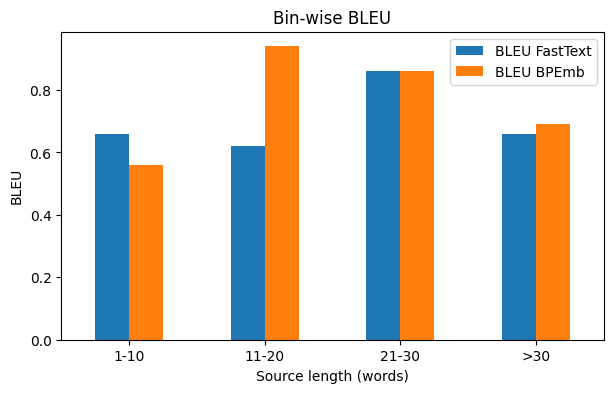

FastText: % outputs containing <unk>: 0.0
Avg length  ref/FastText/BPEmb: 25.5 19.9 18.0


In [8]:
srcs = data["test"][0]
overall = pd.Series({"FastText": bleu(hyp_ft, refs_tok), "BPEmb": bleu(hyp_bp, refs_tok)}).round(2)
print("Overall BLEU:\n", overall, "\n")

b_ft, b_bp = binwise(srcs, hyp_ft, refs_tok), binwise(srcs, hyp_bp, refs_tok)
table = pd.DataFrame({"sentences": b_ft["sentences"], "BLEU FastText": b_ft["bleu"], "BLEU BPEmb": b_bp["bleu"]}).round(2)
table["BPEmb - FastText"] = (table["BLEU BPEmb"] - table["BLEU FastText"]).round(2)
print(table)

table[["BLEU FastText", "BLEU BPEmb"]].plot.bar(figsize=(7, 4))
plt.ylabel("BLEU"); plt.xlabel("Source length (words)"); plt.title("Bin-wise BLEU"); plt.xticks(rotation=0); plt.show()

# extra diagnostics that help the analysis
unk_ft = np.mean([("<unk>" in h) for h in hyp_ft]); print("FastText: % outputs containing <unk>:", round(100 * unk_ft, 1))
print("Avg length  ref/FastText/BPEmb:", round(float(np.mean([len(r.split()) for r in refs_tok])), 1),
      round(float(np.mean([len(h.split()) for h in hyp_ft])), 1), round(float(np.mean([len(h.split()) for h in hyp_bp])), 1))
table.to_csv("binwise_bleu.csv")

## 6. Bin-wise result analysis (fill in after running)
Look at the table and chart above, then discuss:
- **Trend with length:** does BLEU drop as sentences get longer? By how much between the shortest and longest bin? (Typical: long sentences are harder; the Transformer degrades more when training data has few long sentences.)
- **FastText vs BPEmb per bin:** which wins in each bin, and is the gap larger for long or short sentences?
- **Why:** word-level vocabularies leave rare/unseen words as `<unk>` (see the `<unk>` percentage); subwords cover rare and morphologically rich words, which helps most when the vocabulary is large or the data is small. Word embeddings can win on short, frequent-word sentences.
- **Caveats:** bins with few sentences give noisy BLEU (see the `sentences` column); BLEU is lowercased and uses the same word tokenisation for both systems; one training run per system (no seeds averaged).
- **Conclusion:** one or two sentences naming the better embedding and the length range where it matters.